# Intro

* Where Attention fits into the feedforward sweep
* Different tokenizers use slightly different naming conventions
* More about the $QK^T$ matrix in Attention

# V1

## Code

### Imports

In [83]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn import functional as F

In [84]:
#n load GPT2 tokenizer
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

### Hyperparameters

In [85]:
dir(tokenizer)

['SPECIAL_TOKENS_ATTRIBUTES',
 '__annotations__',
 '__bool__',
 '__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_bos_token',
 '_add_eos_token',
 '_add_tokens',
 '_added_tokens_decoder',
 '_added_tokens_encoder',
 '_auto_class',
 '_convert_encoding',
 '_convert_id_to_token',
 '_convert_token_to_id_with_added_voc',
 '_decode',
 '_encode_plus',
 '_eventual_warn_about_too_long_sequence',
 '_extra_special_tokens',
 '_from_pretrained',
 '_get_files_timestamps',
 '_get_padding_truncation_strategies',
 '_in_target_context_manager',
 '_merges',
 '_pad',
 '_pad_token_type_id',
 '_patch_mistral_regex',
 '_post_init',
 

In [86]:
# data hyperparameters
seq_len = 8
n_vocab = tokenizer.vocab_size

# model hyperparameters
embed_dim = 2**6

# training hyperparameters
batch_size = 5

## Model

# New section

In [87]:
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    # embedding matrices
    self.embedding = nn.Embedding(n_vocab, embed_dim) # each i from n_vocab gets a vector of length = embed_dim || i.e. embedding.weight.shape = [n_vocab, embed_dim]
    self.positions = nn.Embedding(seq_len, embed_dim) # each j from seq_len gets a vector of length = embed_dim || i.e. positions.weight.shape = [seq_len, embed_dim]

    # final output linear layer (unembeddings)
    self.final_linear = nn.Linear(embed_dim, n_vocab, bias = False)

    # initialize the k,q,v matrices for attention
    self.layer_norm_A = nn.LayerNorm(embed_dim)
    self.key          = nn.Linear(embed_dim, embed_dim, bias = False)
    self.query        = nn.Linear(embed_dim, embed_dim, bias = False)
    self.value        = nn.Linear(embed_dim, embed_dim, bias = False)
    self.W0           = nn.Linear(embed_dim, embed_dim)

    # the final output layer is tied to the token embedding
    self.final_linear.weight = nn.Parameter(self.embedding.weight)

  def forward(self, tok_x):

    # create the token+position embedding
    # tok_x [1,2,12,33] - each token is from 0 to n_vocab thats why embedding is (n_vocab, embed_dim) -> each token from 0 to n_vocab get vector of length = embed_dim
    token_embed = self.embedding(tok_x) # [batch_size, num_tokens, embed_dim]
    posit_embed = self.positions(torch.arange(tok_x.shape[-1])) # [num_tokens, embed_dim]

    # their sum is the output of the embeddings
    x = token_embed + posit_embed # [batch, num_tokens, embedding_dims]

    ## n --- attention sublayer begins here
    # layernorm before attention
    x = self.layer_norm_A(x)

    # attention algo
    k = self.key(x)
    q = self.query(x)
    v = self.value(x)

    qk = q@k.transpose(-2,-1) # dot product between query and keys
    qk_scaled = qk * embed_dim**-.5
    past_mask = torch.tril(torch.ones(x.shape[0], seq_len, seq_len))
    qk_scaled[past_mask == 0] = -torch.inf
    qk_softmax = F.softmax(qk_scaled, dim = -1)
    y = qk_softmax@v

    y *= self.W0(y)
    #n --- end attention

    # MLP sublayer would be here (next version of the model)

    # final output transformation (unembeddings)
    y = self.final_linear(y) / np.sqrt(embed_dim)

    return y, (past_mask, qk_scaled, qk_softmax) # output some attention matrices for inspection (hooks are better in real models)

  def generate(self, tok_x, temperature = 1, n_new_tokens = 50):

    # tok_x is [batch, tokens]

    for _ in range(n_new_tokens):

        # get predictions, but only from the past seq_len tokens
        x = self(tok_x[:, -seq_len:])[0] # [batch, seq_len, n_vocab]

        # extract the final token to predict the next
        x = x[:,-1,:] # [batch, n_vocab]  // but actually [batch, -1, n_vocab] after squeeze

        # apply softmax to get prbability values over all tokens in the vocab
        probs = F.softmax(x/temperature, dim = -1) #[batch, n_vocab]

        # probabilistically sample from the distribution
        tok_x_next = torch.multinomial(probs, num_samples = 1) # [batch, 1]

        # append
        tok_x = torch.cat((tok_x, tok_x_next), dim = 1) # [batch, (tokens+1)]

    return tok_x

In [88]:
class Module(nn.Module):
  def __init__(self):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.positions = nn.Embedding(seq_len, embed_dim)

    self.final_layer = nn.Linear(embed_dim, n_vocab, bias = False)

    self.layer_norm_A = nn.LayerNorm(embed_dim)

    self.key   = nn.Linear(embed_dim, embed_dim, bias = False)
    self.query = nn.Linear(embed_dim, embed_dim, bias = False)
    self.value = nn.Linear(embed_dim, embed_dim, bias = False)
    self.W0    = nn.Linear(embed_dim, embed_dim)

    self.final_layer.weight = nn.Parameters(self.embedding.weight)

  def forward(self, tok_x):
    token_embed = self.embedding(tok_x)
    token_posit = self.positions(torch.arange(len(tok_x.shape[-1])))

    x = token_embed + posit_embed

    x = self.layer_norm_A(x)

    k = self.key(x)
    q = self.query(x)
    v = self.value(x)

    qk = q@k.transpose(-2,-1) # dot product between query and keys
    qk_scaled = qk * embed_dim**-.5
    past_mask = torch.tril(torch.ones(x.shape[0], seq_len, seq_len))
    qk_scaled[past_mask == 0] = -torch.inf
    qk_softmax = F.softmax(qk_scaled, dim = -1)
    y = qk_softmax@v

    y *= self.W0(y)

    y = self.final_layer(y) / np.sqrt(embed_dim)

    return y, (past_mask, qk_scaled, qk_softmax)

  def generate(self, tok_x, temperature = 1, n_new_tokens = 50):

    # tok_x is [batch, tokens]

    for _ in range(n_new_tokens):

        x = self(tok_x[:, -seq_len:])[0] # [batch, seq_len, n_vocab]

        x = x[:,-1,:] # [batch, n_vocab]

        probs = F.softmax(x/temperature, dim = -1) #[batch, n_vocab]

        tok_x_next = torch.multinomial(probs, num_samples = 1) # [batch, 1]

        tok_x = torch.cat((tok_x, tok_x_next), dim = 1) # [batch, (tokens+1)]

    return tok_x

## Logits

In [89]:
# create data
tokens = tokenizer.encode('I prefer oat milk in my coffee.')
X = torch.tensor(tokens[:-1]).unsqueeze(0)
y = torch.tensor(tokens[1:]).unsqueeze(0)

print(X.shape)
print(y.shape)

torch.Size([1, 8])
torch.Size([1, 8])


In [90]:
model = Model()
out, attn = model(X)

print(out.shape)

torch.Size([1, 8, 50257])


In [91]:
print('Time-causal mask:\n', attn[0])
print('\nqk_scaled:\n', attn[1])
print('\nqk_softmax:\n',attn[2])

Time-causal mask:
 tensor([[[1., 0., 0., 0., 0., 0., 0., 0.],
         [1., 1., 0., 0., 0., 0., 0., 0.],
         [1., 1., 1., 0., 0., 0., 0., 0.],
         [1., 1., 1., 1., 0., 0., 0., 0.],
         [1., 1., 1., 1., 1., 0., 0., 0.],
         [1., 1., 1., 1., 1., 1., 0., 0.],
         [1., 1., 1., 1., 1., 1., 1., 0.],
         [1., 1., 1., 1., 1., 1., 1., 1.]]])

qk_scaled:
 tensor([[[ 0.0243,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf,
             -inf],
         [ 0.1094,  0.4480,    -inf,    -inf,    -inf,    -inf,    -inf,
             -inf],
         [-0.1235,  0.1940, -0.4215,    -inf,    -inf,    -inf,    -inf,
             -inf],
         [-0.0076,  0.0845,  0.0896, -0.3269,    -inf,    -inf,    -inf,
             -inf],
         [-0.0247, -0.0249,  0.7481, -0.4272,  0.2247,    -inf,    -inf,
             -inf],
         [ 0.3264,  0.2739, -0.2732, -0.1281,  0.0671,  0.3801,    -inf,
             -inf],
         [ 0.0388, -0.2516, -0.1127,  0.0596,  0.3229, -0.3151, 

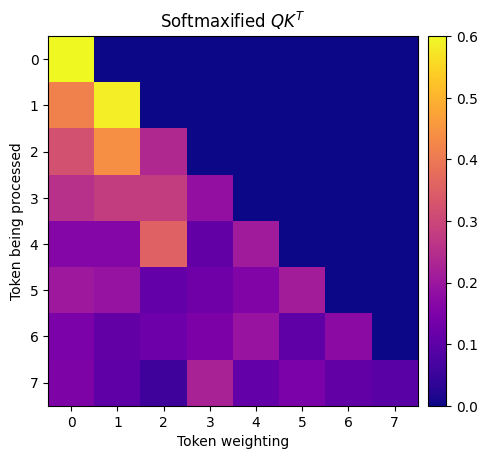

In [92]:
plt.imshow(attn[2].detach().squeeze(), vmin = 0, vmax = .6, cmap = 'plasma')
plt.gca().set(xlabel='Token weighting', ylabel = 'Token being processed', title = 'Softmaxified $QK^T$')
plt.colorbar(pad = .02)
plt.show()

In [93]:
# sanity-check
attn[2].detach().squeeze().sum(dim=1)

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

## Generate Text

In [94]:
# start with some new tokens
text = "When I grow up, I want to be a"
tokens = tokenizer.encode(text)
tokens = torch.tensor(tokens).unsqueeze(0)

generated_tokens = model.generate(tokens, temperature=2, n_new_tokens = 10)[0]

tokenizer.decode(generated_tokens.tolist())

'When I grow up, I want to be a chambers JumpExcept destroy alien volatileuties018 hallucinations Altern'

Repeat with different temperature values

In [95]:
temps = [.2, .7, 1, 2, 10]

for T in temps:
  tokz = model.generate(tokens, temperature= T, n_new_tokens=10)
  tokz = tokz[0].tolist()
  print(f'Temp = {T}:\n {tokenizer.decode(tokz)}\n')

Temp = 0.2:
 When I grow up, I want to be arail SpeakHttp lesser EARequired worksLOG">< Variable

Temp = 0.7:
 When I grow up, I want to be a issue humanitiesumin spot scrib elites Batmarine referees 39

Temp = 1:
 When I grow up, I want to be afulRu VT Rus Denmark autobiography ages678 DENPrim

Temp = 2:
 When I grow up, I want to be aidding super cropsorld unfortunate corp▬ having DEL Diss

Temp = 10:
 When I grow up, I want to be achukif Using BolConsumer Baylor clergy relativesissanceVarious



# Model 0 - One Attention Head

## Imports

In [96]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [97]:
from transformers import GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

In [98]:
dir(tokenizer)

['SPECIAL_TOKENS_ATTRIBUTES',
 '__annotations__',
 '__bool__',
 '__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_bos_token',
 '_add_eos_token',
 '_add_tokens',
 '_added_tokens_decoder',
 '_added_tokens_encoder',
 '_auto_class',
 '_convert_encoding',
 '_convert_id_to_token',
 '_convert_token_to_id_with_added_voc',
 '_decode',
 '_encode_plus',
 '_eventual_warn_about_too_long_sequence',
 '_extra_special_tokens',
 '_from_pretrained',
 '_get_files_timestamps',
 '_get_padding_truncation_strategies',
 '_in_target_context_manager',
 '_merges',
 '_pad',
 '_pad_token_type_id',
 '_patch_mistral_regex',
 '_post_init',
 

## Hyperparameters

In [99]:
seq_len    = 8
embed_dim  = 2**6
batch_size = 10
n_vocab    = tokenizer.vocab_size

## Model

$$
Q = XW_Q,\quad K = XW_K,\quad V = XW_V
$$

$$
A =
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}} + M
\right)
$$

$$
H = AV
$$

$$
\operatorname{CausalAttention}(Q,K,V)
=
H W_O
=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}} + M
\right)
V W_O
$$

$$
M_{ij}
=
\begin{cases}
0, & j \le i \\
-\infty, & j > i
\end{cases}
$$

In [157]:
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    self.token_embeddings   = nn.Embedding(n_vocab, embed_dim)
    self.posit_embeddings   = nn.Embedding(seq_len, embed_dim)

    self.layer_norm_1       = nn.LayerNorm(embed_dim)
    self.key   = nn.Linear(embed_dim, embed_dim, bias = False)
    self.query = nn.Linear(embed_dim, embed_dim, bias = False)
    self.value = nn.Linear(embed_dim, embed_dim, bias = False)
    self.W0    = nn.Linear(embed_dim, embed_dim)

    self.final_layer        = nn.Linear(embed_dim, n_vocab)
    self.final_layer.weight = nn.Parameter(self.token_embeddings.weight)

  def forward(self, tok_x):

    token_embeddings = self.token_embeddings(tok_x) # [batch_size, num_tokens, embed_dim]
    posit_embeddings = self.posit_embeddings(torch.arange(tok_x.shape[-1])) # [num_tokens, embed_dim]

    x = token_embeddings + posit_embeddings # [batch_size, num_tokens, embed_dim]

    x = self.layer_norm_1(x) # [batch_size, num_tokens, embed_dim]

    k = self.key(x)   # [batch_size, num_tokens, embed_dim]
    q = self.query(x) # [batch_size, num_tokens, embed_dim]
    v = self.value(x) # [batch_size, num_tokens, embed_dim]

    qk = q@k.transpose(-2,-1) # [batch_size, num_tokens, num_tokens]
    qk_scaled = qk * embed_dim**(-0.5)
    qk_softmax = F.softmax(qk_scaled, dim = -1)
    y = qk_softmax@v
    y = self.W0(y)

    y = self.final_layer(y) / np.sqrt(embed_dim)

    return y

  def generate(self, tok_x, temperature = 1, n_new_tokens = 20):

    for _ in range(n_new_tokens):
      x        = self(tok_x[:,-seq_len:]) # [batch_size, seq_len, embed_dim]
      logs     = x[:,-1,:] # [batch_size, embed_dim]
      probs    = F.softmax(logs/temperature, dim = -1) # [batch_size, embed_dim]
      next_tok = torch.multinomial(probs, num_samples = 1) # [batch, 1]
      tok_x    = torch.cat((tok_x, next_tok), dim = 1)

    return tok_x

## Deconstruction

### forward()

#### `tok_embed`, `pos_embed`

In [101]:
tok_x  = torch.randint(0, n_vocab, (batch_size, seq_len))
token_embeddings = nn.Embedding(n_vocab, embed_dim)

tok_embed = token_embeddings(tok_x)
tok_embed.shape

torch.Size([10, 8, 64])

`nn.Embedding` accepts 2 values: `(num_embeddings, embedding_dim)`. In our example, `num_embeddings` is `n_vocab`, i.e. the input to `nn.Embedding` contains integer indices, and each number must be lower than `num_embeddings` (in our example, lower than `n_vocab`). `embedding_dim` is the length of the vector assigned to each index. For example, `tok_x` has shape `[batch_size, num_tokens]`, meaning each element inside `tok_x` is a token ID from `0` to `n_vocab - 1`. The outcome is that for every batch and every token, we get an embedding vector of length `embedding_dim`; therefore, `token_embeddings` has shape `[batch_size, num_tokens, embed_dim]`.


In [102]:
position_embeddings = nn.Embedding(seq_len, embed_dim)

pos_embed = position_embeddings(torch.arange(tok_x.shape[-1]))
pos_embed.shape

torch.Size([8, 64])

It works same for position embeddings, here we pass arange of length `num_tokens` taken from `tok_x`. That causes, than each index of arange get the embedding vector.

In [103]:
x = tok_embed + pos_embed
x.shape

torch.Size([10, 8, 64])

`pos_embed` are being added to last 2 dimensions of `tok_embed` and broadcasted through every batch. Eventually we get shape of `[batch_size, num_tokens, embed_dim]`.

#### `layer_norm_1`

In [104]:
import copy

x_pre_norm = copy.deepcopy(x.detach())

In [105]:
layer_norm = nn.LayerNorm(embed_dim)
x = layer_norm(x)
x.shape

torch.Size([10, 8, 64])

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_24442/1343297862.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(pre_dist,  'b-o', label = f'Pre- Norm embed_dim | $\mu = {pre_mean:>10.1f}$ | $\sigma = {pre_std:.1f}$')
/tmp/ipykernel_24442/1343297862.py:14: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(pre_dist,  'b-o', label = f'Pre- Norm embed_dim | $\mu = {pre_mean:>10.1f}$ | $\sigma = {pre_std:.1f}$')
/tmp/ipykernel_24442/1343297862.py:15: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(post_dist, 'r-o', label = f'Pre- Norm embed_dim | $\mu = {post_mean:>10.1f}$ | $\sigma = {post_std:.

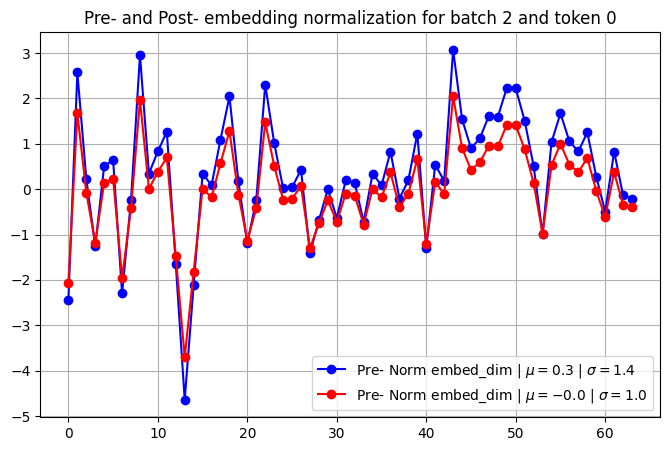

In [106]:
rand_batch = torch.randint(0,batch_size,(1,)).item()
rand_token = torch.randint(0,x.shape[1],(1,)).item()

plt.figure(figsize = (8,5))

pre_dist  = x_pre_norm[rand_batch,rand_token,:].detach()
pre_mean = pre_dist.mean()
pre_std  = pre_dist.std()

post_dist = x[rand_batch,rand_token,:].detach()
post_mean = post_dist.mean()
post_std  = post_dist.std()

plt.plot(pre_dist,  'b-o', label = f'Pre- Norm embed_dim | $\mu = {pre_mean:>10.1f}$ | $\sigma = {pre_std:.1f}$')
plt.plot(post_dist, 'r-o', label = f'Pre- Norm embed_dim | $\mu = {post_mean:>10.1f}$ | $\sigma = {post_std:.1f}$')

plt.title(f'Pre- and Post- embedding normalization for batch {rand_batch} and token {rand_token}')
plt.legend()
plt.grid()
plt.show()

Normalization changes last dimension into $\mu = 0$ and $\sigma = 1$ what we can experience. So, last dimension which is `embed_dim` gets above parameters, in simpler words, each each token, in each batch, has vector of `embed_dim` length, this vector for each token gets normalized.

One question is why we need to pass `embed_dim` in `__init__` in `nn.LayerNorm(embed_dim)`? `nn.LayerNorm()` either way always takes last dimenion and normalizes on last dimension, then why we need to give a shape of last dimension in `__init__`? Well, that's because we want to give all parameters in `__init__`, that's how after just class instantion we can check model parameters:

In [107]:
model = Model()

for i in model.parameters():
  print(i.shape)

torch.Size([50257, 64])
torch.Size([8, 64])
torch.Size([64])
torch.Size([64])
torch.Size([64, 64])
torch.Size([64, 64])
torch.Size([64, 64])
torch.Size([64, 64])
torch.Size([64])
torch.Size([50257, 64])
torch.Size([50257])


Developers theoretically could make LayerNorm infer the last dimension during the first forward pass, but then parameters like LayerNorm.weight and LayerNorm.bias would not exist immediately after __init__.

That would make model.parameters(), state_dict(), and optimizer initialization less straightforward before the first forward pass.

#### `k`,`q`,`v`

First, $W_Q$, $W_K$, $W_V$ are the raw learnable weight matrices.
Q, K, V are the projected matrices after multiplying X by those weights:

$$Q = XW_Q$$
$$K = XW_K$$
$$V = XW_V$$

in code we named $W_Q$, $W_K$, $W_V$ by `query`, `key`, `value` variables.

In [108]:
key   = nn.Linear(embed_dim, embed_dim, bias = False)
query = nn.Linear(embed_dim, embed_dim, bias = False)
value = nn.Linear(embed_dim, embed_dim, bias = False)

K = key(x)
Q = query(x)
V = value(x)

K.shape, Q.shape, V.shape

(torch.Size([10, 8, 64]), torch.Size([10, 8, 64]), torch.Size([10, 8, 64]))

`nn.Linear(x)` is just a dot product `x@[embed_dim,embed_dim].T`

In [109]:
embed_dim_matrix_key   = torch.randn(embed_dim, embed_dim)
embed_dim_matrix_query = torch.randn(embed_dim, embed_dim)
embed_dim_matrix_value = torch.randn(embed_dim, embed_dim)

K = x@embed_dim_matrix_key.T
Q = x@embed_dim_matrix_query.T
V = x@embed_dim_matrix_value.T

K.shape, Q.shape, V.shape

(torch.Size([10, 8, 64]), torch.Size([10, 8, 64]), torch.Size([10, 8, 64]))

We get exactly same results.

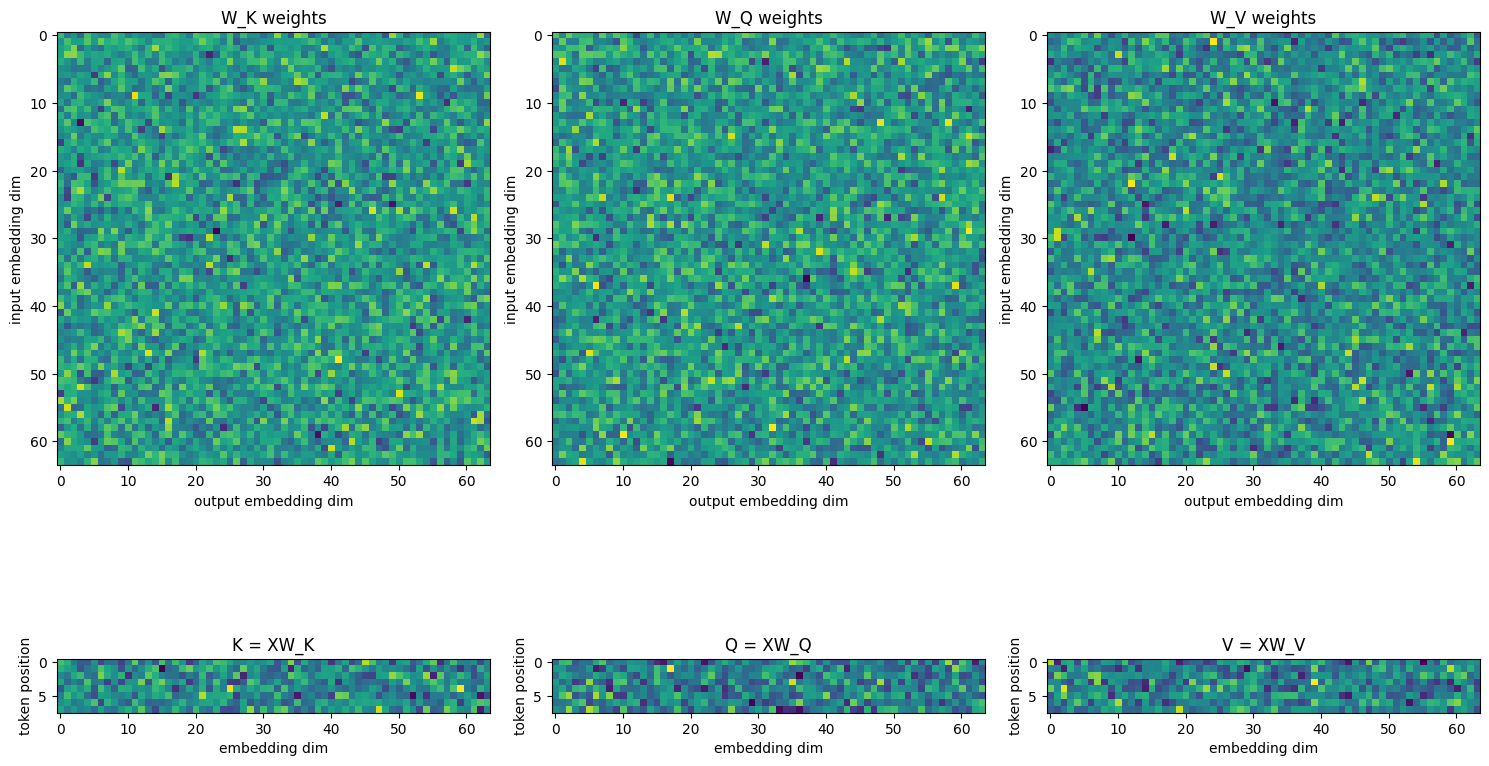

In [110]:
weights  = [embed_dim_matrix_key, embed_dim_matrix_query, embed_dim_matrix_value]
matrices = [K, Q, V]

weight_titles = ["W_K weights", "W_Q weights", "W_V weights"]
matrix_titles = ["K = XW_K", "Q = XW_Q", "V = XW_V"]

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
axs = axs.flatten()

# plot weight matrices
for i, w in enumerate(weights):
    axs[i].imshow(w.detach() if hasattr(w, "detach") else w)
    axs[i].set_title(weight_titles[i])
    axs[i].set_xlabel("output embedding dim")
    axs[i].set_ylabel("input embedding dim")

# plot projected K, Q, V matrices for first batch
for i, m in enumerate(matrices):
    axs[i + 3].imshow(m.detach()[0])
    axs[i + 3].set_title(matrix_titles[i])
    axs[i + 3].set_xlabel("embedding dim")
    axs[i + 3].set_ylabel("token position")

plt.tight_layout()
plt.show()

Since $W,Q,K$ are of shapes `[embed_dim,embed_dim]` and $x$ is of shape `[batch_size, num_tokens, embed_dim]` (taken from last step) we do the multiplication on last 2 dimensions matrices, so for x `[num_tokens, embed_dim]` and for $W,Q,K$ `[embed_dim, embed_dim]` after matrix multiplication we receive shape of `[num_tokens, embed_dim]` which is broadcasted through all batches, so eventually we receive `[batch_size, num_tokens, embed_dim]`.

#### `qk`

In [111]:
K.shape, Q.shape

(torch.Size([10, 8, 64]), torch.Size([10, 8, 64]))

In [112]:
print(K.shape)
Kt = K.transpose(-2,-1)
print(Kt.shape)

torch.Size([10, 8, 64])
torch.Size([10, 64, 8])


In [113]:
Q.shape, Kt.shape

(torch.Size([10, 8, 64]), torch.Size([10, 64, 8]))

So we multiply $Q$ of shape `[8,64]` with $K$ of shape `[64,8]`, and this is broadcasted through all 10 batches.

The rules of multiplying more than 2 dimension matrices are:

1. We multiply actually 2 last dimensions, so when we have `[10, 8, 64]` and `[10, 64, 8]` we can multiply it because `[8, 64]` and `[64, 8]` is multipliable
2. We broadcast multiplication through all other dimensions
3. All other dimension need to either be the same, or one of them needs to be one. If are the same we broadcast same amount of times in a given dim, if only one dim is one we stretch one dim into non-one dim.
4. 3 implies that number of dimensions of 2 tensors must match

That's why we do `k.transpose(-2,-1)`, $Q$ and $K$ are both same shape tensors, we need to transpose on 2 last dimensions $k$ to make multiplication valid and broadcast it through all bathces.

That also why the output shape of $QK.T$ is in `[batch_size, num_tokens, num_toknes]`. $Q$ is given by `[batch_size, num_tokens, embed_dim]`, $K.T$ (on 2 last dimensions) is given by `[batch_size, embed_dim, num_tokens]`, then `[num_tokens, embed_dim] @ [embed_dim, num_tokens]` returns `[num_tokens, num_tokens]`, with broadcasting we get `[batch_size, num_tokens, num_tokens]`.

In [114]:
QKt = Q@Kt
QKt.shape

torch.Size([10, 8, 8])

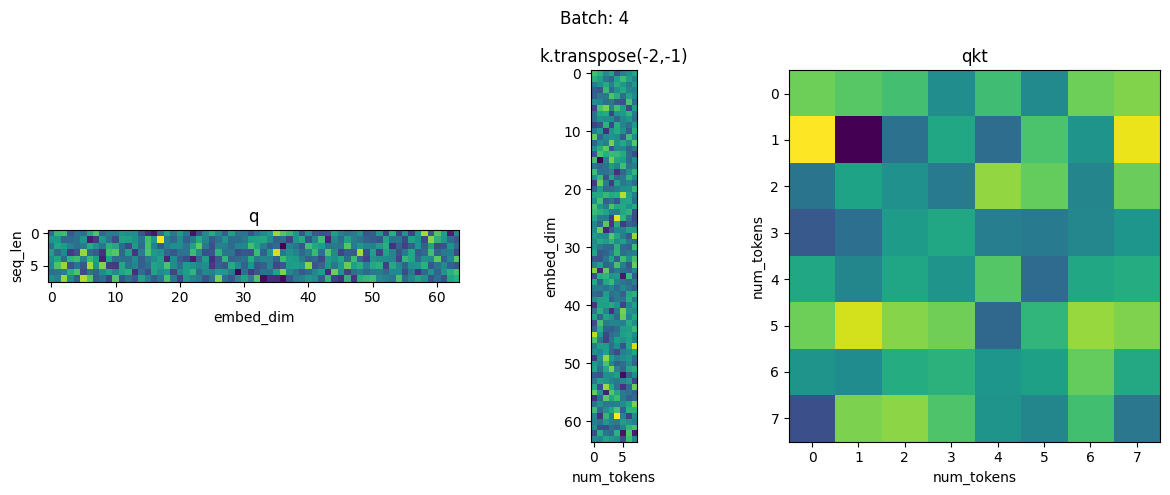

In [115]:
fig, axs = plt.subplots(1,3,figsize = (12,5))

batch = torch.randint(0,batch_size,(1,))

axs[0].imshow(Q.detach()[0])
axs[0].set_title('q')
axs[0].set_xlabel('embed_dim')
axs[0].set_ylabel('seq_len')

axs[1].imshow(Kt.detach()[0])
axs[1].set_title('k.transpose(-2,-1)')
axs[1].set_ylabel('embed_dim')
axs[1].set_xlabel('num_tokens')

axs[2].imshow(QKt.detach()[0])
axs[2].set_title('qkt')
axs[2].set_xlabel('num_tokens')
axs[2].set_ylabel('num_tokens')

fig.suptitle(f'Batch: {batch.item()}')

plt.tight_layout()
plt.show()

#### qk_scaled

In [116]:
qk_scaled = QKt * embed_dim**(-0.5)
qk_scaled.shape

torch.Size([10, 8, 8])

It's of course just division by square root of `embed_dim`.

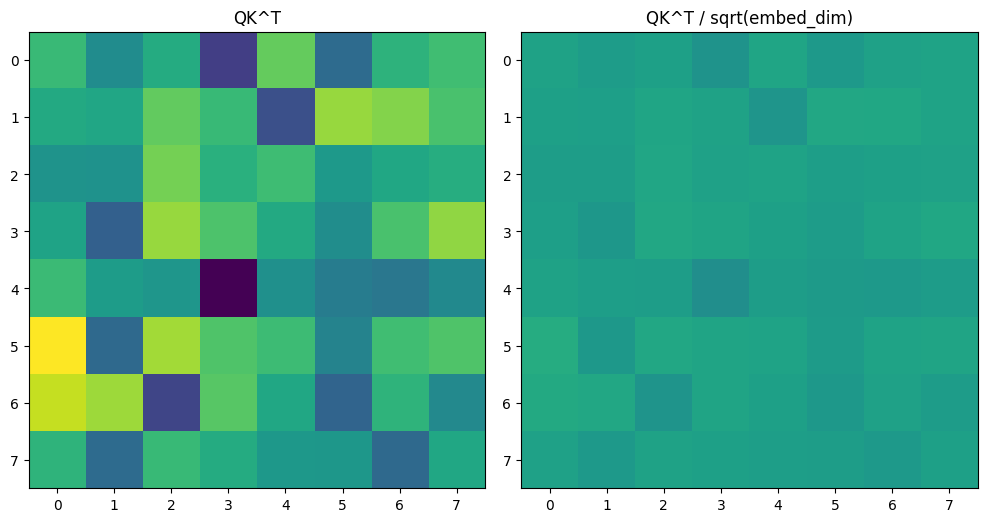

In [117]:
vmin = QKt[rand_batch].min().item()
vmax = QKt[rand_batch].max().item()

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(QKt[rand_batch].detach().squeeze(), vmin=vmin, vmax=vmax)
axs[0].set_title("QK^T")

axs[1].imshow(qk_scaled[rand_batch].detach().squeeze(), vmin=vmin, vmax=vmax)
axs[1].set_title("QK^T / sqrt(embed_dim)")

plt.tight_layout()
plt.show()

We divide by $\sqrt{\text{embed_dim}}$ because the dot product $q \cdot k$ sums over $\text{embed_dim}$ values.

As $\text{embed_dim}$ grows, the variance of $q \cdot k$ grows roughly like $\text{embed_dim}$, so its standard deviation grows like $\sqrt{\text{embed_dim}}$.

Dividing by $\sqrt{\text{embed_dim}}$ keeps attention scores in a stable range before softmax.

Without it, softmax becomes too sharp too early, almost like picking one token only.

$$
q \cdot k = \sum_{i=1}^{d_k} q_i k_i
$$

$$
\operatorname{Var}(q \cdot k) \approx d_k
$$

$$
\operatorname{Std}(q \cdot k) \approx \sqrt{d_k}
$$

$$
\frac{q \cdot k}{\sqrt{d_k}}
$$

#### `M` (mask)

In [118]:
past_mask = torch.tril(torch.ones(batch_size, seq_len, seq_len))
qk_scaled[past_mask == 0] = -torch.inf

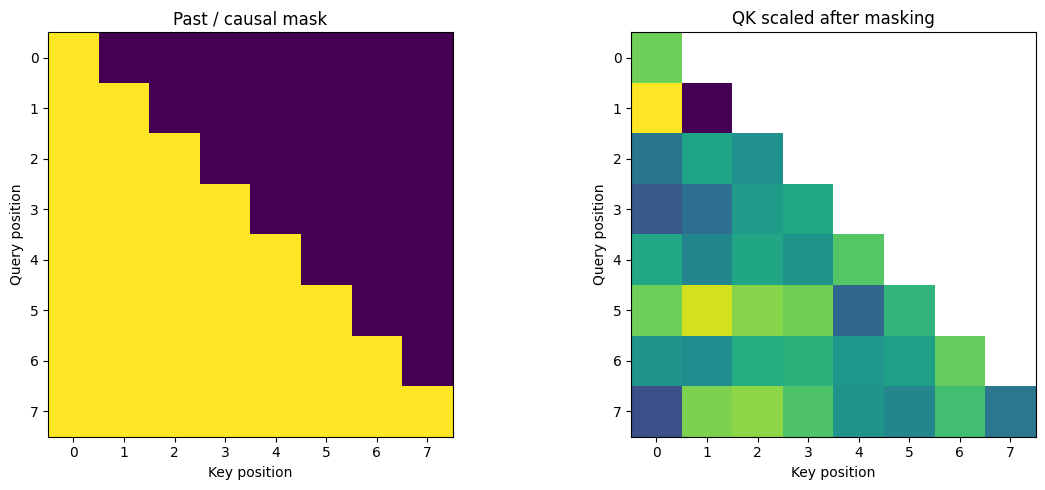

tensor([[1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])
tensor([[  52.6655,      -inf,      -inf,      -inf,      -inf,      -inf,
              -inf,      -inf],
        [ 119.3956, -182.4980,      -inf,      -inf,      -inf,      -inf,
              -inf,      -inf],
        [ -66.3263,   -7.6972,  -30.1631,      -inf,      -inf,      -inf,
              -inf,      -inf],
        [ -98.7684,  -72.8109,  -16.5633,   -1.3410,      -inf,      -inf,
              -inf,      -inf],
        [  -2.0123,  -44.3056,   -5.4024,  -25.8699,   39.9343,      -inf,
              -inf,      -inf],
        [  52.1791,   99.1767,   64.4209,   53.3652,  -81.1572,   15.6864,
              -inf,      -inf],
        [ -25.7102,  

In [119]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# 1) causal / past mask
axs[0].imshow(past_mask[0].detach().cpu())
axs[0].set_title("Past / causal mask")
axs[0].set_xlabel("Key position")
axs[0].set_ylabel("Query position")

# 2) masked attention scores
axs[1].imshow(qk_scaled[0].detach().cpu())
axs[1].set_title("QK scaled after masking")
axs[1].set_xlabel("Key position")
axs[1].set_ylabel("Query position")

plt.tight_layout()
plt.show()

print(past_mask[0])
print(qk_scaled[0])

`past_mask` simulates time, so at top we have single word, and going forward we add more words. The thing is that the model is causal, meaning it needs to see ONLY the past. Text given for training shows also future, so we want to hide it from model, so it will be able to predict new tokens without knowing future ones.

Adding infinity instead of 0's, is just for softmax. Softmax will turn

In [120]:
F.softmax(torch.tensor([1,2,0.]), dim = 0)

tensor([0.2447, 0.6652, 0.0900])

In [121]:
F.softmax(torch.tensor([1, 2, -torch.inf]), dim = 0)

tensor([0.2689, 0.7311, 0.0000])

As we can see sofmtax for 0's is not 0, we want it to be just 0 that's why we get negative infinity in place of 0's.

#### `qk_softmax`

`qk_scaled` has same dimension as `qk` `[batch_size, num_tokens, num_tokens]`. We do softmax on last dimension `dim = -1`.

In [122]:
qk_scaled.shape

torch.Size([10, 8, 8])

In [123]:
qk_softmax = F.softmax(qk_scaled, dim = -1)
qk_softmax.shape

torch.Size([10, 8, 8])

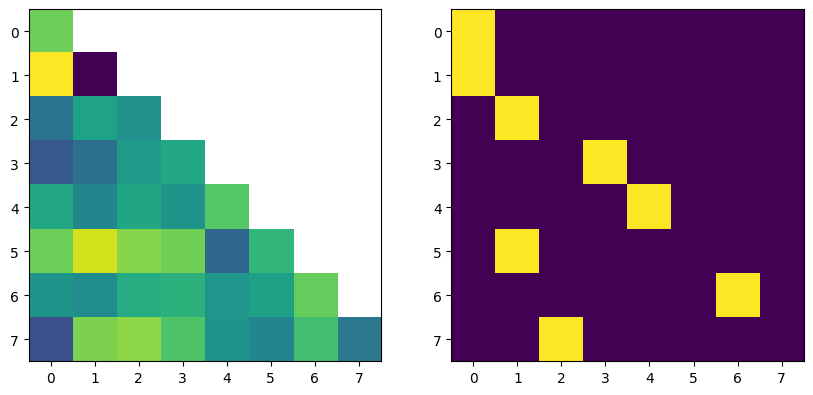

In [124]:
fig, axs = plt.subplots(1,2, figsize = (10,5))

axs[0].imshow(qk_scaled[ 0].detach())
axs[1].imshow(qk_softmax[0].detach())

As we can see in last sequence only token of index 1 fired. 7th sequence tries to predict token 8th, i.e. for prediction of token 8th the highest importance has token 1.

The attention mechanism returns a probability distribution over the previous tokens, representing their relative importance for building the current token representation, which is then used to predict the next token in the sequence.

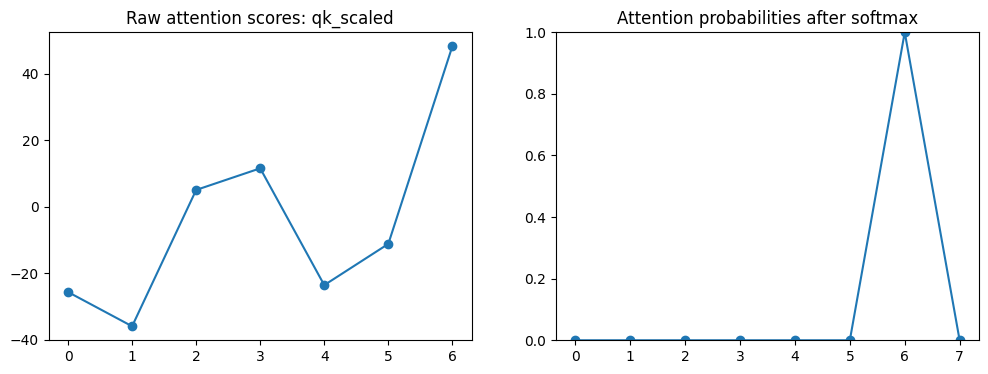

In [125]:
fig, axs = plt.subplots(1, 2, figsize=(12,4))

axs[0].plot(qk_scaled[0,-2,:].detach(), '-o')
axs[0].set_title("Raw attention scores: qk_scaled")

axs[1].plot(qk_softmax[0,-2,:].detach(), '-o')
axs[1].set_title("Attention probabilities after softmax")
axs[1].set_ylim(0, 1)

plt.show()

Now, one very important thing: when we try to predict the token at index 7, attention looks at the previous tokens. But why do we need previous tokens?

The word “probability” can be misleading here. It is better to think of attention weights as a normalized distribution of importance, or scale factors.

This distribution tells us how much information we should take from each previous token to build the context representation for the current position. From that context representation, the model then predicts the next token.

So the previous tokens are not being predicted. They are used to represent the context for predicting the token at index 7. Attention tells us how important each previous token is for building that context.

#### `qk_sotfmax@v`

In [126]:
qk_softmax.shape, V.shape

(torch.Size([10, 8, 8]), torch.Size([10, 8, 64]))

In [127]:
y = qk_softmax@V
y.shape

torch.Size([10, 8, 64])

Before multiplication with $V$ we have `[batch_size, num_tokens, num_tokens]` after we receive `[batch_size, num_tokens, embed_dim]`.

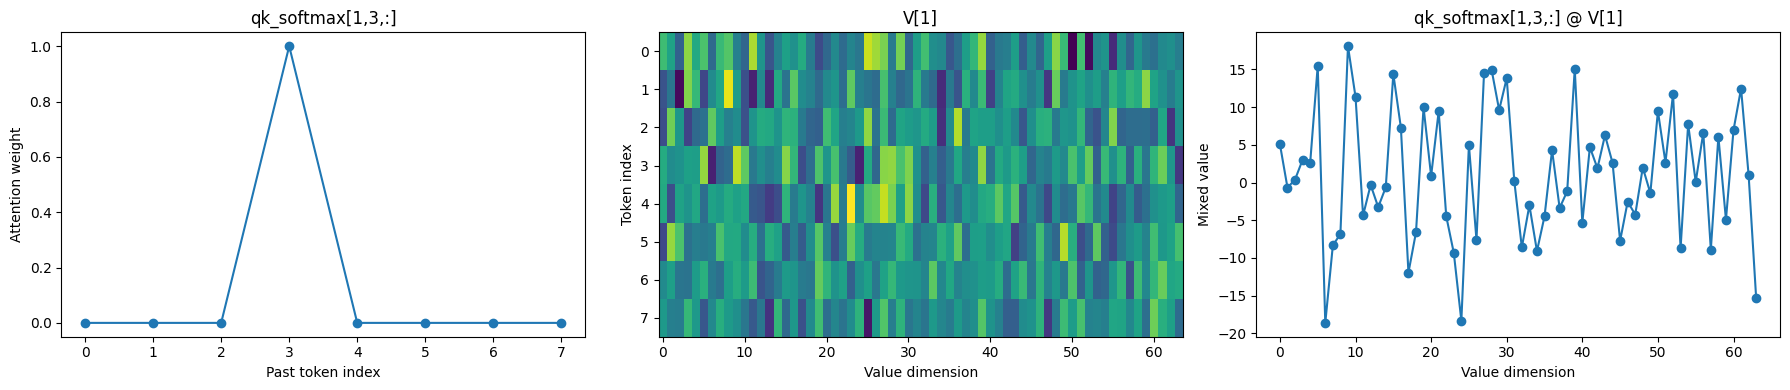

In [128]:
b = 1
t = 3

attn = qk_softmax[b, t, :]      # [8]
v_mat = V[b]                    # [8, 64]
prod = attn @ v_mat             # [64]

fig, axs = plt.subplots(1, 3, figsize=(18, 4))

axs[0].plot(attn.detach(), "-o")
axs[0].set_title(f"qk_softmax[{b},{t},:]")
axs[0].set_xlabel("Past token index")
axs[0].set_ylabel("Attention weight")

axs[1].imshow(v_mat.detach(), aspect="auto")
axs[1].set_title(f"V[{b}]")
axs[1].set_xlabel("Value dimension")
axs[1].set_ylabel("Token index")

axs[2].plot(prod.detach(), "-o")
axs[2].set_title(f"qk_softmax[{b},{t},:] @ V[{b}]")
axs[2].set_xlabel("Value dimension")
axs[2].set_ylabel("Mixed value")

plt.tight_layout()
plt.show()

For position 3, qk_softmax gives attention weights over previous tokens.

Then we multiply these weights by V:

attention_weights @ V

This means: take a weighted mixture of value vectors from previous tokens.

So if token 1 has weight 0.9, most of the new context vector comes from V[1].
If token 2 has weight 0.1, a small part comes from V[2].
Tokens with weight near 0 contribute almost nothing.

The product is one new vector of size 64.
This vector is the context representation for position 3, and later it is used to predict the next token.

In simple words, for each token position, attention attaches back a mixed value vector of length embed_dim.

#### `y=W0(y)`

In [129]:
import copy

y_pre = copy.copy(y)

In [130]:
y_pre.shape

torch.Size([10, 8, 64])

In [131]:
W0 = nn.Linear(embed_dim, embed_dim)
W0y = W0(y_pre)
W0y.shape

torch.Size([10, 8, 64])

After attention, every token gets back a mixed value vector. qk_softmax decides which previous tokens matter. V contains the information from those tokens. W0 then rewrites this mixed information back into the model space, so the next layer can use it.

Simple intuition:

* qk_softmax @ V = collect information
* W0(y) = rewrite it into useful model language

In [132]:
y = W0y

In [133]:
y.shape

torch.Size([10, 8, 64])

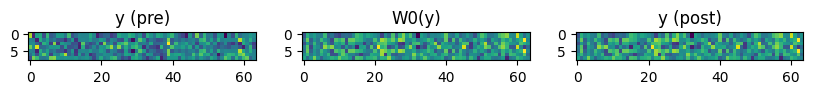

In [134]:
_, axs = plt.subplots(1,3,figsize = (10,5))

axs[0].imshow(y_pre.detach()[0])
axs[0].set_title('y (pre)')
axs[1].imshow(W0y.detach()[0])
axs[1].set_title('W0(y)')
axs[2].imshow(y.detach()[0])
axs[2].set_title('y (post)')

plt.show()

* y = information
* W0(y) = learned gate/control signal
* y *= W0(y) = keep/use only what the model decides is useful

#### `self.final_layer(y) / np.sqrt(embed_dim)`

In [135]:
final_layer = nn.Linear(embed_dim, n_vocab)
final_layer.weight = nn.Parameter(token_embeddings.weight)

y_pre = copy.copy(y)

y = final_layer(y_pre) / np.sqrt(embed_dim)

In [136]:
y_pre.shape, y.shape

(torch.Size([10, 8, 64]), torch.Size([10, 8, 50257]))

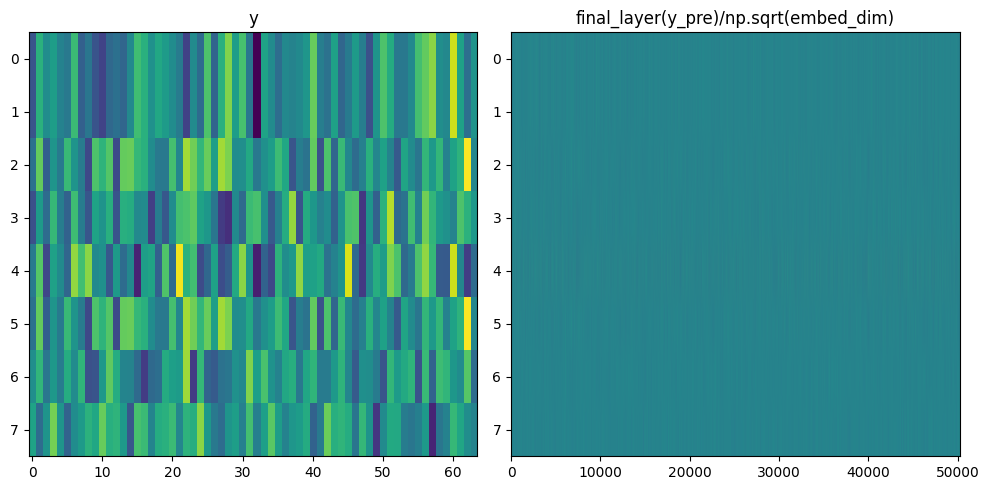

In [137]:
_, axs = plt.subplots(1,2,figsize=(10,5))

axs[0].imshow(y_pre.detach()[0], aspect = 'auto')
axs[0].set_title('y')
axs[1].imshow(y.detach()[0],     aspect = 'auto')
axs[1].set_title('final_layer(y_pre)/np.sqrt(embed_dim)')

plt.tight_layout()
plt.show()

At this stage, we project each token vector from `embed_dim` to `n_vocab` using final_layer. So shape changes from `[batch, seq_len, embed_dim]` to `[batch, seq_len, n_vocab]`. This gives one logit score for every possible next token.

We divide by `sqrt(embed_dim)` to keep the scale of logits under control.

### generate()

generate() function design depends on what kind of behavior we want from the model.

For example, the model can:

* take text and return one next word/token

* take text with missing words and fill the blanks

* take a question and return a chat-like answer

* take a prompt and continue the text

* take instructions and return a structured output

So generate() is not one fixed thing. It is just the wrapper that controls how model outputs are turned into final text. This particular `generate()` function we build, takes some sentence, e.g. "I believe I can fly, I believe I" and model return as many new tokens we specify in `n_new_tokens`.

#### self(`tok_x[:,-seq_len:]`)


For generate() we need processed forward() function. However, we have ongoing `y` in `forward()` subsection which we can use as `self()`. `self()` is just a reference to built-in `forward()` function, i.e. `tok_x[:,-seq_len:]` goes through `forward()` function

`tok_x` represents input data, it has 10 batches with length of 8 each. Now, `seq_len` is 8. `tok_x` lenght is same as `seq_len` therefore we `tok_x[:,-seq_len:]` = `tok_x` in this particular example. In general the idea is that for each batch we take last `seq_len` tokens a sequence from which we want to make prediction of next token. That means we always feed the model with last `seq_len` tokens for prediction, no more.

In [138]:
tok_x.shape, seq_len

(torch.Size([10, 8]), 8)

In [139]:
y.shape

torch.Size([10, 8, 50257])

Since, `tok_x` has same width as `seq_len`, i.e. input data to forwad `tok_x` had `seq_len` width, and input to `self()` (`tok_x[:,-seq_len:]`) also has width of `seq_len` we can just do `x = y`, but it actually means `x = self(tok_x[:,-seq_len:])`

Let's apply this mental shortcut

In [140]:
x = y # actually means x = self(tok_x[:,-seq_len:]) - shortcut to keep same flow out of instantiated Model class

In [141]:
x.shape

torch.Size([10, 8, 50257])

Our `x` at this point has shape of `[batch_size, seq_len, n_vocab]`. Let's note one important thing, in `forward()` subsection instead of `seq_len` we used `num_tokens` as shape even though in our example `seq_len` = `num_toknes` because we generated `tok_x` with width equal to `seq_len`. However, we didn't have to do that, in forward `num_tokens` can be any positive integer, meaning we can pass to the model sentences of any length for training (later we have constraint of `context_length` which we don't use in current version of the model). BUT, in `generate()` function we take last `seq_len` tokens and we use only them to predict next token. That's why here we need to rename `num_tokens` into `seq_len`.

#### `x[:,-1,:]`

In [142]:
x.shape

torch.Size([10, 8, 50257])

In [143]:
logs = x[:,-1,:]
logs.shape

torch.Size([10, 50257])

In this step we simply take,

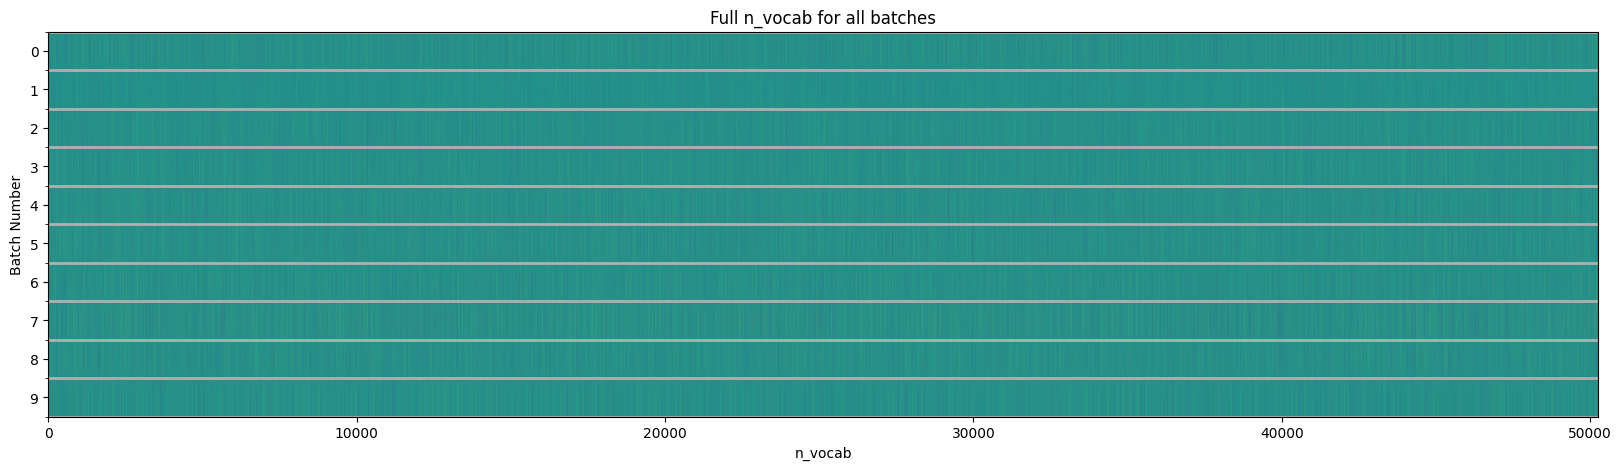

In [144]:
plt.figure(figsize=(20,5))

plt.imshow(logs.detach(), aspect='auto')

plt.yticks(np.arange(logs.shape[0]))

ax = plt.gca()
ax.set_yticks(np.arange(-0.5, logs.shape[0], 1), minor=True)
ax.grid(which='minor', axis='y', linewidth=2)
ax.grid(which='major', axis='y', alpha=0)

plt.ylabel('Batch Number')
plt.xlabel('n_vocab')

plt.title('Full n_vocab for all batches')

plt.show()

Let's see a close-up.

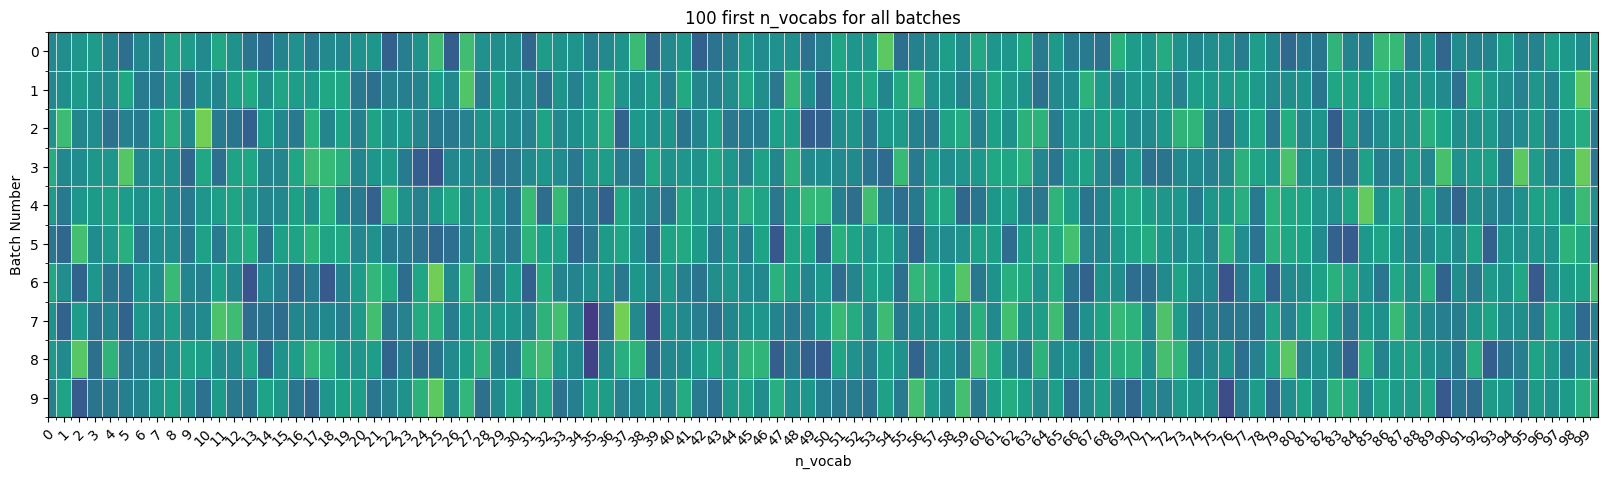

In [145]:
plt.figure(figsize=(20,5))

plt.imshow(logs.detach(), aspect='auto')

plt.ylabel('Batch Number')
plt.xlabel('n_vocab')

ax = plt.gca()

# batch grid
ax.set_yticks(np.arange(logs.shape[0]))
ax.set_yticks(np.arange(-0.5, logs.shape[0], 1), minor=True)

# vocab grid
ax.set_xticks(np.arange(0,100))
ax.set_xticks(np.arange(-0.5,100,1), minor=True)

# draw grids
ax.grid(which='minor', color='white', linewidth=0.5)

plt.xlim([0,100])
plt.xticks(np.arange(100), rotation=45)

plt.title('100 first n_vocabs for all batches')

plt.show()

As we can see each batch is assembled from `n_vocab` values. It's important to note that even though we got matrix of `[batch_size, n_vocab]` it's actually `[batch_size, last_token (1), n_vocab]` meaning we took last token of `seq_len`. Now, this is important because that means last token (actually all of them but we care about last one) is represented by `n_vocab` length vector. This representation is specifc to given token in terms of the context of that token in whole text (corpus) on which we've trained our model. In other words, this vector of `n_vocab` length is a distribution of "pre-probabilities" of next token, or in oother words logits.

In [146]:
logits = logs[0].detach()

topk = 100
values, indices = torch.topk(logits, topk)

plt.figure(figsize=(250, 40))

# all logits
plt.plot(logits, 'o', alpha=0.25, markersize = 20)

# top 100 logits
plt.plot(indices, values, 'ro', markersize=20)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

Those are logits for the next token in batch 0, computed from the final position, which contains information from the whole context window. At top we can see 100 highest logits. The next token will be sampled from this distribution, and the top 100 logits are the strongest candidates.

#### F.softmax(logs/temperature, dim = -1)

Changes logits into probabilities. We do softmax on last dimension, i.e. on `n_vocab`.

$$
\text{softmax}_T(x_i)
=
\frac{e^{x_i/T}}
{\sum_{j=1}^{n} e^{x_j/T}}
$$

The higher Temperature

In [147]:
temps = np.linspace(1, 10, 10)

rand_batch = torch.randint(0, batch_size, (1,)).item()

fig, axs = plt.subplots(10, 1, figsize=(40, 80), sharex=True)

for i, temperature in enumerate(temps):
    probs = F.softmax(logs / temperature, dim=-1)
    p = probs[rand_batch].detach()

    axs[i].plot(p, 'bo', alpha=.5, markersize=8)
    axs[i].set_title(f'Temperature = {temperature:.1f}, batch {rand_batch}', fontsize=20)
    axs[i].set_ylabel('Probability', fontsize=16)

axs[-1].set_xlabel('Vocabulary token index', fontsize=20)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

As we can see, the higher temperature the more tokens are probable of being selected. High Temperature means, that we add more variability into our prediction. We usually use high temperature for more sophisticated models, like generating poems or some other creative tasks, while we use high temperature when we want to be more technical and precise.

#### `torch.multinomial(probs, num_samples = 1)`

This function simply selects 1 sample token with probability defined in probs. Let's only remember that we have 10 batches, so the output should have 10 values, i.e. 10 tokens each for one batch.

In [148]:
next_tok = torch.multinomial(probs, num_samples = 1)
next_tok

tensor([[49027],
        [26521],
        [42204],
        [43227],
        [24080],
        [15795],
        [42589],
        [ 9801],
        [44482],
        [15797]])

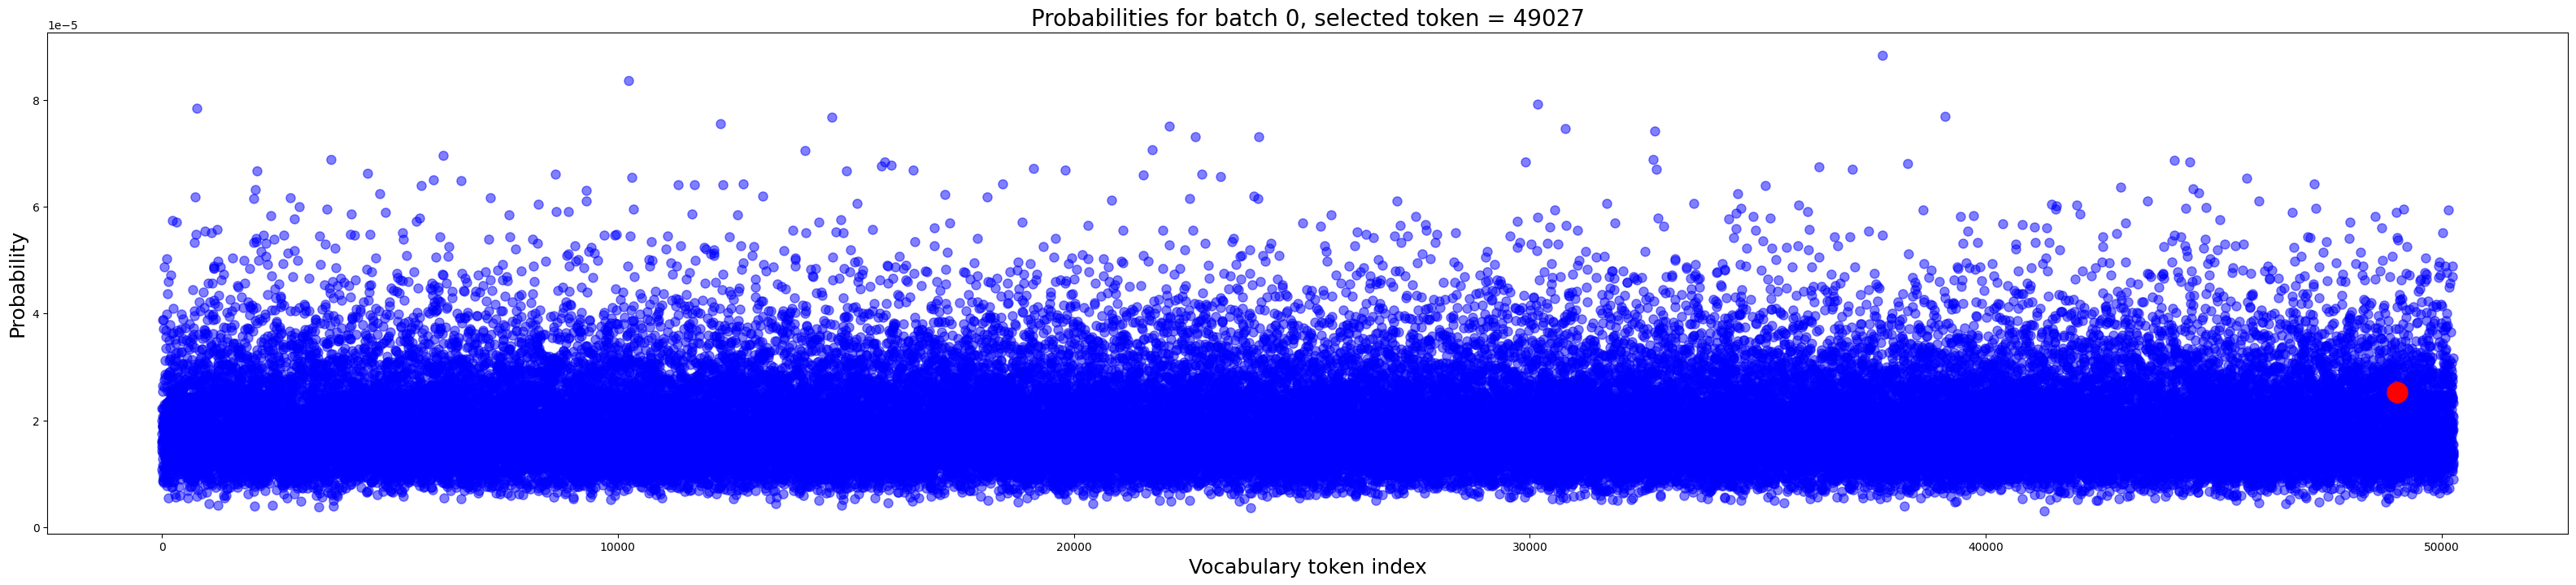

In [149]:
batch_id = 0

p = probs[batch_id].detach()
selected_token = next_tok[batch_id].item()
selected_prob = p[selected_token]

plt.figure(figsize=(40, 8))

plt.plot(p, 'bo', alpha=.5, markersize=8)
plt.plot(selected_token, selected_prob, 'ro', markersize=18)

plt.title(f'Probabilities for batch {batch_id}, selected token = {selected_token}', fontsize=20)
plt.xlabel('Vocabulary token index', fontsize=18)
plt.ylabel('Probability', fontsize=18)

plt.show()

As we can see choosen token didn't have highest probability. Our Temperature in above plot is 10, due to that the variability is quite high. We can see which token would be selected with Temperature = 1.

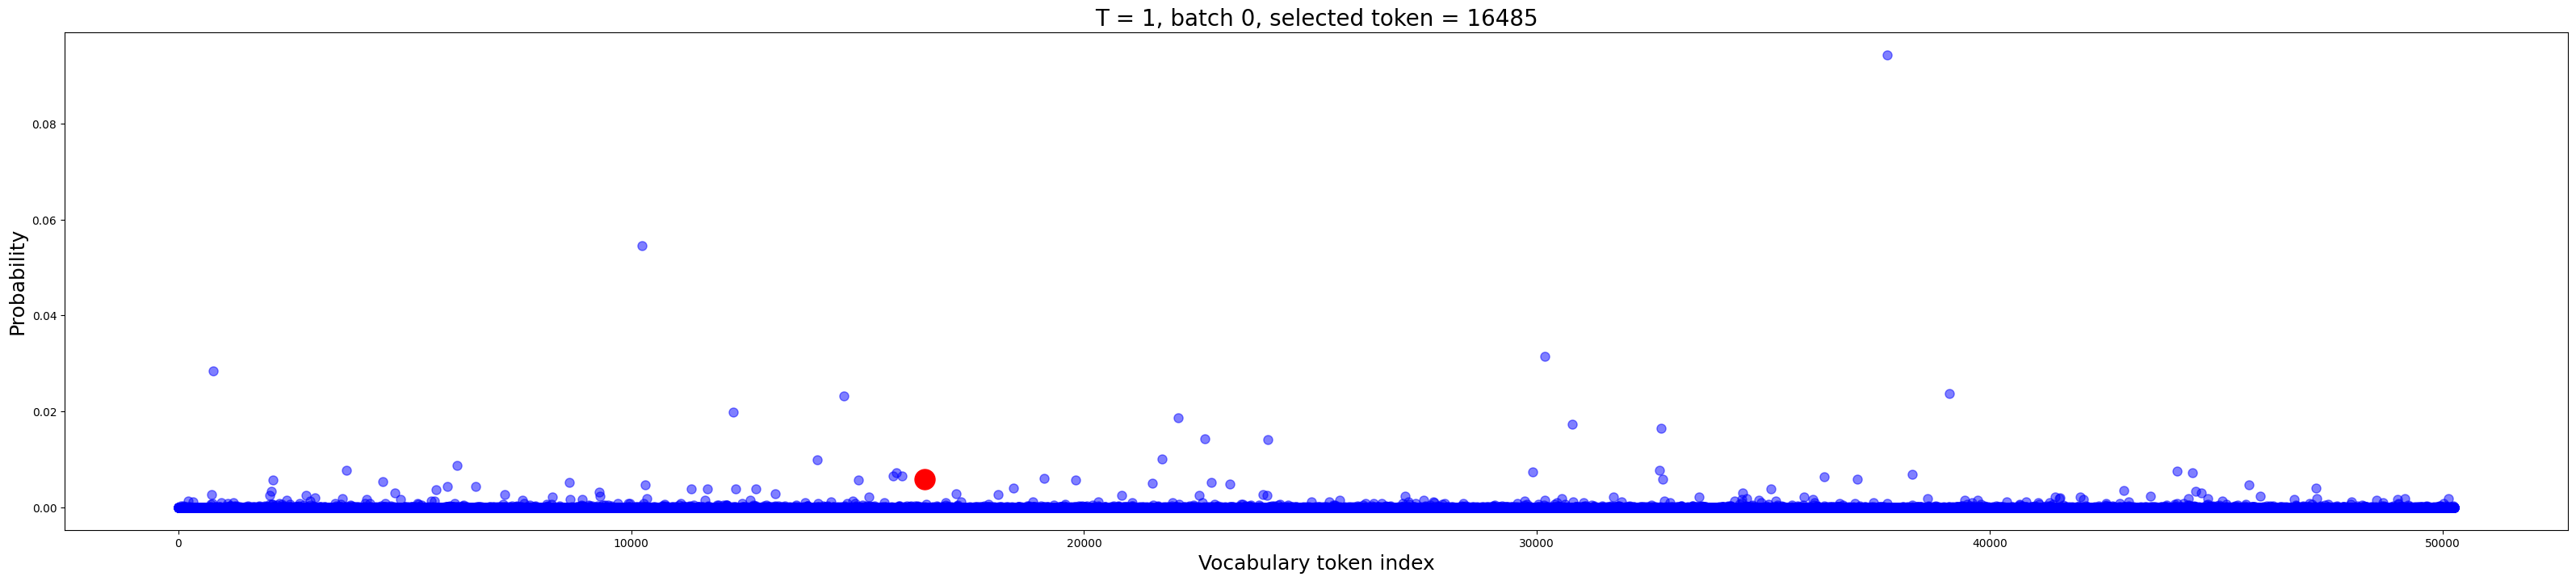

In [150]:
T = 1

probs = F.softmax(logs / T, dim=-1)

next_tok = torch.multinomial(probs, num_samples=1)

batch_id = 0

p = probs[batch_id].detach()
selected_token = next_tok[batch_id].item()
selected_prob = p[selected_token]

plt.figure(figsize=(40, 8))

plt.plot(p, 'bo', alpha=.5, markersize=8)
plt.plot(selected_token, selected_prob, 'ro', markersize=18)

plt.title(f'T = {T}, batch {batch_id}, selected token = {selected_token}', fontsize=20)
plt.xlabel('Vocabulary token index', fontsize=18)
plt.ylabel('Probability', fontsize=18)

plt.show()

Temperature 1 assures predictability, now selected token obviously has highest probability.

#### `torch.cat((tok_x, next_tok), dim = 1)`

In [151]:
tok_x.shape

torch.Size([10, 8])

In [152]:
tok_x = torch.cat((tok_x, next_tok), dim = 1)
tok_x.shape

torch.Size([10, 9])

We can see that `tok_x` before cat has 8 tokens per batch, after `cat` we have 9 tokens per batch. We simply add selected next token to initial `tok_x`. In `generate()` function we specify `n_new_tokens`, meaning we repeat whole generation `n_new_tokens` times, or add same amount tokens to input for each batch. Let's remember that input always has length of `seq_len`, so input window slides 1 token forward each time.

## Text Generation

In [163]:
model = Model()

text = "I believe I can fly, I believe"
text_encoded = torch.tensor(tokenizer.encode(text)) # We need to have torch tensor
text_encoded = text_encoded.unsqueeze(0) # We need to unsqueeze, so from shape [num_tokens] we're doing [batch_size, num_tokens]
                                         # in our example batch_size = 1 since we have 1 sentence but we need to specify this in dimension
text_encoded.shape

torch.Size([1, 8])

In [164]:
text_generated_encoded = model.generate(text_encoded, temperature = 2, n_new_tokens = 10)
text_generated_encoded

tensor([[   40,  1975,   314,   460,  6129,    11,   314,  1975, 34330,  2580,
         31978, 43137,  8265, 16528, 25199, 29121, 21567, 46213]])

In [165]:
text_generated_decoded = tokenizer.decode(text_generated_encoded)
text_generated_decoded

['I believe I can fly, I believerather Che Bucc Velocity modulesson Swordsitudinal Rollingusha']